In [1]:
import os
import sys


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from enums import *
from contract import *
from model import *
from market_data import *
from pricer import *

MarketData.initialize()

## First try

In [3]:
# Setting contract and choosing the range of the strikes:  70%-130%
underlying = Stock.BLUECHIP_BANK
spot = MarketData.get_spot()[underlying]

Pricer.relative_bump_size = Pricer.absolute_bump_size / spot

strikes = np.linspace(0.7 * spot, 1.3 * spot, 100)

expiry = 1.0
contracts = []
for K in strikes:
    c = EuropeanContract(
        underlying=underlying,
        derivative_type=PutCallFwd.CALL,
        long_short=LongShort.LONG,
        strike=K,
        expiry=expiry
    )
    contracts.append(c)

In [4]:
# computing the analytic values
model = FlatVolModel(underlying)
analytic_results = []
for contract in contracts:
    pricer = EuropeanAnalyticPricer(contract, model, Params())
    analytic_delta = pricer.calc_delta(GreekMethod.ANALYTIC)
    analytic_gamma = pricer.calc_gamma(GreekMethod.ANALYTIC)
    analytic_results.append({
        'strike': contract.strike,
        'analytic_delta': analytic_delta,
        'analytic_gamma': analytic_gamma
    })

analytic_df = pd.DataFrame(analytic_results)
analytic_df.head()

,strike,analytic_delta,analytic_gamma
0,91.119000,0.854848,0.003468
1,91.907909,0.851389,0.003536
2,92.696818,0.847885,0.003605
3,93.485727,0.844336,0.003674
4,94.274636,0.840742,0.003744


In [5]:
# computing values over different types of bumps and different finite diff methods
fd_methods = [FiniteDifferenceMethod.FORWARD, FiniteDifferenceMethod.BACKWARD, FiniteDifferenceMethod.CENTRAL]
bump_types = [BumpType.ABSOLUTE, BumpType.RELATIVE]

numerical_results = []
for contract in contracts:
    for fd in fd_methods:
        for bump in bump_types:
            Pricer.fd_method = fd
            Pricer.bump_type = bump
            pricer = EuropeanAnalyticPricer(contract, model, Params())
            num_delta = pricer.calc_delta(GreekMethod.BUMP)
            num_gamma = pricer.calc_gamma(GreekMethod.BUMP)
            numerical_results.append({
                'strike': contract.strike,
                'fd_method': fd.value,
                'bump_type': bump.value,
                'num_delta': num_delta,
                'num_gamma': num_gamma
            })

numerical_df = pd.DataFrame(numerical_results)
numerical_df.head(12)

,strike,fd_method,bump_type,num_delta,num_gamma
0,91.119000,FORWARD,ABSOLUTE,0.855021,0.003459
1,91.119000,FORWARD,RELATIVE,0.855021,0.003459
2,91.119000,BACKWARD,ABSOLUTE,0.854674,0.003476
3,91.119000,BACKWARD,RELATIVE,0.854674,0.003476
4,91.119000,CENTRAL,ABSOLUTE,0.854847,0.003468
5,91.119000,CENTRAL,RELATIVE,0.854847,0.003468
6,91.907909,FORWARD,ABSOLUTE,0.851566,0.003528
7,91.907909,FORWARD,RELATIVE,0.851566,0.003528
8,91.907909,BACKWARD,ABSOLUTE,0.851212,0.003544
9,91.907909,BACKWARD,RELATIVE,0.851212,0.003544


In [6]:
merged_df = pd.merge(numerical_df, analytic_df, on='strike')

merged_df['delta_error'] = merged_df['num_delta'] - merged_df['analytic_delta']
merged_df['gamma_error'] = merged_df['num_gamma'] - merged_df['analytic_gamma']
merged_df['delta_rel_error'] = merged_df['delta_error'] / merged_df['analytic_delta']
merged_df['gamma_rel_error'] = merged_df['gamma_error'] / merged_df['analytic_gamma']

error_cols = ['delta_error', 'gamma_error', 'delta_rel_error', 'gamma_rel_error']
merged_df.groupby(['fd_method', 'bump_type'])[error_cols].agg(lambda x: x.abs().mean())

delta_error   gamma_error  delta_rel_error  \
fd_method bump_type                                                
BACKWARD  ABSOLUTE   3.404446e-04  7.656243e-06     6.434997e-04   
          RELATIVE   3.404446e-04  7.656243e-06     6.434997e-04   
CENTRAL   ABSOLUTE   1.276147e-07  1.710825e-09     1.984769e-07   
          RELATIVE   1.276147e-07  1.710825e-09     1.984769e-07   
FORWARD   ABSOLUTE   3.402000e-04  7.657494e-06     6.431354e-04   
          RELATIVE   3.402000e-04  7.657494e-06     6.431354e-04   

                     gamma_rel_error  
fd_method bump_type                   
BACKWARD  ABSOLUTE      1.295948e-03  
          RELATIVE      1.295948e-03  
CENTRAL   ABSOLUTE      2.499121e-07  
          RELATIVE      2.499121e-07  
FORWARD   ABSOLUTE      1.295471e-03  
          RELATIVE      1.295471e-03

backward and forward error will overlap on the graph

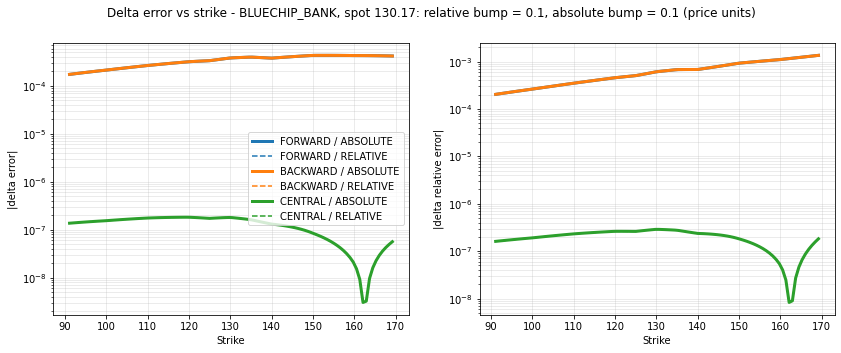

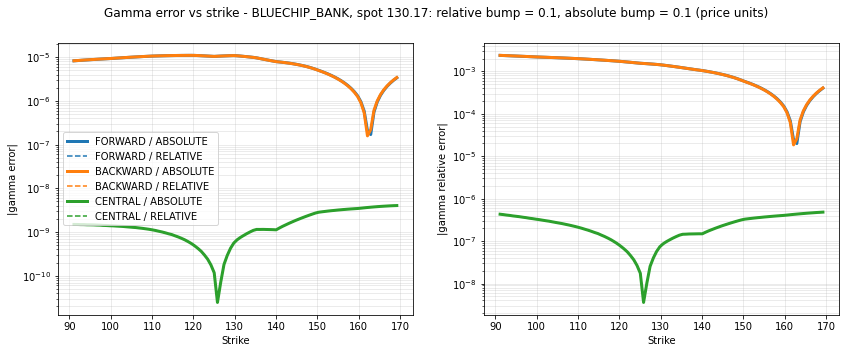

In [15]:
# plotting the absolute error
# for plotting I used AI
colors = {'FORWARD': 'tab:blue', 'BACKWARD': 'tab:orange', 'CENTRAL': 'tab:green'}


def plot_errors_vs_strike(df, greek, title):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    for ax, col, ylabel in zip(axes, [f'{greek}_error', f'{greek}_rel_error'],
                               [f'|{greek} error|', f'|{greek} relative error|']):
        for fd in fd_methods:
            for bump in bump_types:
                d = df[(df['fd_method'] == fd.value) & (df['bump_type'] == bump.value)]
                is_abs = bump == BumpType.ABSOLUTE
                ax.semilogy(d['strike'], d[col].abs().clip(lower=1e-18),color=colors[fd.value],
                            linestyle='-' if is_abs else '--', linewidth=3 if is_abs else 1.5,
                            label=f'{fd.value} / {bump.value}')
        ax.set_xlabel('Strike')
        ax.set_ylabel(ylabel)
        ax.grid(True, which='both', alpha=0.3)
    axes[0].legend()
    fig.suptitle(title)
    plt.show()


bump_info = f'relative bump = {Pricer.relative_bump_size * spot:.3g}, absolute bump = {Pricer.absolute_bump_size:.3g} (price units)'
plot_errors_vs_strike(merged_df, 'delta', f'Delta error vs strike - {underlying.value}, spot {spot:.2f}: {bump_info}')
plot_errors_vs_strike(merged_df, 'gamma', f'Gamma error vs strike - {underlying.value}, spot {spot:.2f}: {bump_info}')

note that forward and backword are overlapping on the graph
## Comparison

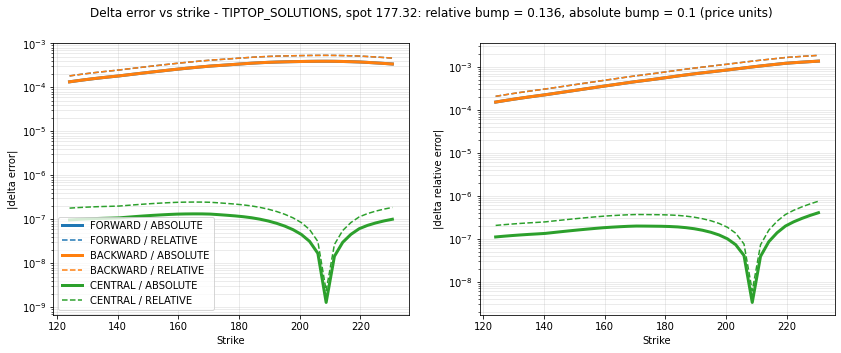

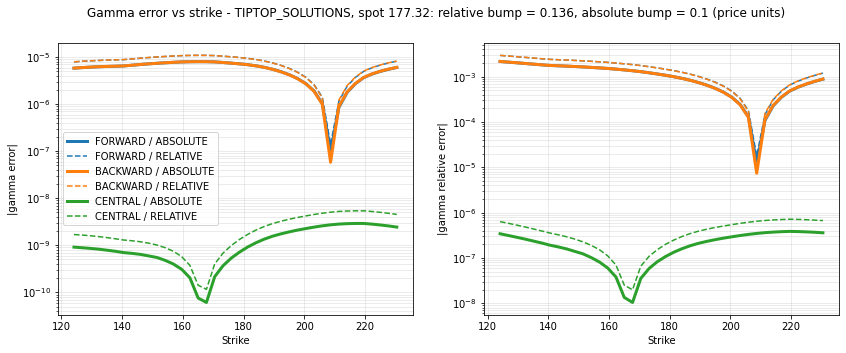

In [8]:
def build_error_df(stock, expiry, n_strikes=40):
    stock_spot = MarketData.get_spot()[stock]
    stock_model = FlatVolModel(stock)
    rows = []
    for K in np.linspace(0.7 * stock_spot, 1.3 * stock_spot, n_strikes): 
        contract = EuropeanContract(stock, PutCallFwd.CALL, LongShort.LONG, K, expiry)
        ref = EuropeanAnalyticPricer(contract, stock_model, Params())
        true_delta = ref.calc_delta(GreekMethod.ANALYTIC)
        true_gamma = ref.calc_gamma(GreekMethod.ANALYTIC)
        for fd in fd_methods:
            for bump in bump_types:
                Pricer.fd_method = fd
                Pricer.bump_type = bump
                p = EuropeanAnalyticPricer(contract, stock_model, Params())
                delta_error = p.calc_delta(GreekMethod.BUMP) - true_delta
                gamma_error = p.calc_gamma(GreekMethod.BUMP) - true_gamma
                rows.append({'strike': K, 'fd_method': fd.value, 'bump_type': bump.value,
                             'delta_error': delta_error, 'gamma_error': gamma_error,
                             'delta_rel_error': delta_error / true_delta,
                             'gamma_rel_error': gamma_error / true_gamma})
    return pd.DataFrame(rows)


stock2 = Stock.TIPTOP_SOLUTIONS
spot2 = MarketData.get_spot()[stock2]
df2 = build_error_df(stock2, expiry)
bump_info2 = f'relative bump = {Pricer.relative_bump_size * spot2:.3g}, absolute bump = {Pricer.absolute_bump_size:.3g} (price units)'
plot_errors_vs_strike(df2, 'delta', f'Delta error vs strike - {stock2.value}, spot {spot2:.2f}: {bump_info2}')
plot_errors_vs_strike(df2, 'gamma', f'Gamma error vs strike - {stock2.value}, spot {spot2:.2f}: {bump_info2}')

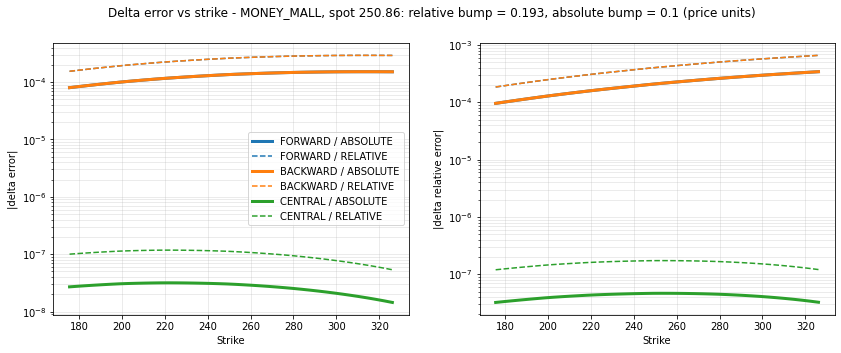

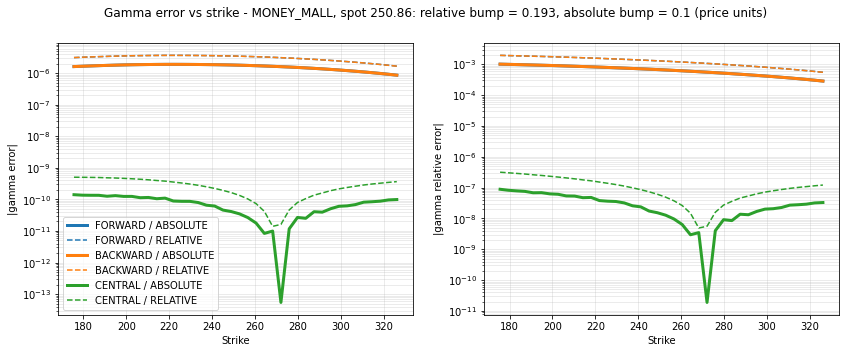

In [9]:
stock3 = Stock.MONEY_MALL
spot3 = MarketData.get_spot()[stock3]
df3 = build_error_df(stock3, expiry)
bump_info3 = f'relative bump = {Pricer.relative_bump_size * spot3:.3g}, absolute bump = {Pricer.absolute_bump_size:.3g} (price units)'
plot_errors_vs_strike(df3, 'delta', f'Delta error vs strike - {stock3.value}, spot {spot3:.2f}: {bump_info3}')
plot_errors_vs_strike(df3, 'gamma', f'Gamma error vs strike - {stock3.value}, spot {spot3:.2f}: {bump_info3}')

MoneyMall is the one whose spot differs more from the other two. This is where choosing between relative or absolute bump size makes an actual difference across different underlyings. 

For several graphs we see a drip.  this is because the error switches sign (negative or positive) and therefore crosses 0 (except that we did not exactly go over that specific strike with that value).


For **Bluechip Bank** the one that does not have a a drip is the forward / backward error for delta. 
That is because the error is ±bumpsize/2 * gamma. And gamma is always positive so it doesnt cross 0. The central finite diff. method does cross zero because the error is $bumpsize^2 *\frac{1}{6} * derivative of gamma$. which crosses 0 when gamma is flat in the spot. The forward, backward and central finite diff methods for gamma also depend on first or second derivative of gamma. which cross zero :)

The dips happen approximately at
- strike 162 for central delta and back-/forward gamma (125% of spot)
- strike 126 for central gamma 

For **TipTopSolutions** the result is simular. The dips happen at
- 209 for central delta and back-/forward gamma (118% of spot)
- 166 central gamma

Why do they have simular results: its because they have simular volatilities. (0.325, 0.381)


**MoneyMall** 
- central delta and back-/forward gamma is out of the picture (much higher)
- 270 central gamma dip. 
Because volitality of money mall is much higher. 

## Optimal bump size 



to find the optimal bumpsize we will now look at the error as a function of bump size. We will take the average over multiple strikes to get one number per bump size. 
We will use central method with relative bump size. Relative is expected to work better when looking at one bump size accross the different underlyings. 

In [16]:
relative_bumps = np.logspace(-9, -1, 17)
stocks = [Stock.BLUECHIP_BANK, Stock.TIPTOP_SOLUTIONS, Stock.MONEY_MALL]

bump_used_above = Pricer.relative_bump_size
sweep_results = []
for stock in stocks:
    for bump in relative_bumps:
        Pricer.relative_bump_size = bump
        df = build_error_df(stock, expiry, n_strikes=10)
        central_relative = df[(df['fd_method'] == 'CENTRAL') & (df['bump_type'] == 'RELATIVE')]
        sweep_results.append({
            'stock': stock.value,
            'relative_bump': bump,
            'delta_error': central_relative['delta_error'].abs().mean(),
            'gamma_error': central_relative['gamma_error'].abs().mean()
        })
Pricer.relative_bump_size = bump_used_above

sweep_df = pd.DataFrame(sweep_results)

for greek in ['delta', 'gamma']:
    best = sweep_df.loc[sweep_df.groupby('stock')[f'{greek}_error'].idxmin(), ['stock', 'relative_bump', f'{greek}_error']]
    print(best.to_string(index=False), '\n')

           stock  relative_bump  delta_error
   BLUECHIP_BANK       0.000003 1.453929e-11
      MONEY_MALL       0.000003 1.025586e-11
TIPTOP_SOLUTIONS       0.000003 1.249215e-11 

           stock  relative_bump  gamma_error
   BLUECHIP_BANK         0.0001 6.636880e-11
      MONEY_MALL         0.0001 3.469306e-11
TIPTOP_SOLUTIONS         0.0001 9.787314e-11 



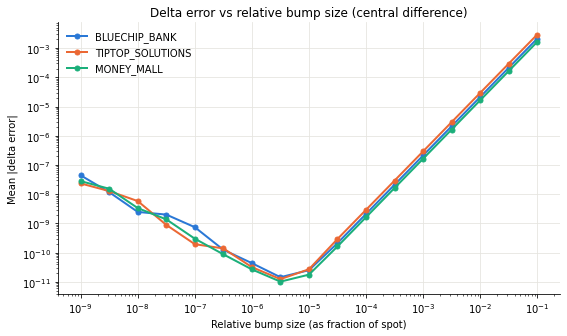

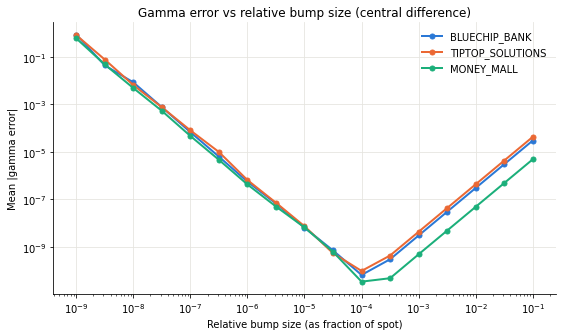

In [12]:
# for plotting I used AI
stock_colors = {Stock.BLUECHIP_BANK.value: '#2a78d6', 
                Stock.TIPTOP_SOLUTIONS.value: '#eb6834', 
                Stock.MONEY_MALL.value: '#1baf7a'}


def plot_error_vs_bump(df, greek, title):
    fig, ax = plt.subplots(figsize=(9, 5))
    for stock, color in stock_colors.items():
        d = df[df['stock'] == stock]
        ax.loglog(d['relative_bump'], d[f'{greek}_error'].clip(lower=1e-18), color=color, linewidth=2,
                  marker='o', markersize=5, label=stock)
    ax.set_xlabel('Relative bump size (as fraction of spot)')
    ax.set_ylabel(f'Mean |{greek} error|')
    ax.grid(True, which='major', color='#e5e4df', linewidth=0.8)
    ax.spines[['top', 'right']].set_visible(False)
    ax.legend(frameon=False)
    ax.set_title(title)
    plt.show()


plot_error_vs_bump(sweep_df, 'delta', 'Delta error vs relative bump size (central difference)')
plot_error_vs_bump(sweep_df, 'gamma', 'Gamma error vs relative bump size (central difference)')

## Conclusions
Best relative bumpsize for the delta would be 0.000003 and for gamma 0.0001. I think both are fine options because at both bumpsizes both errors are small. 